# Part 1 - Data Preparation

In [1]:
import pandas as pd
import numpy as np

In [3]:
# Loading dataset
df =pd.read_csv('/content/diabetes.csv')

In [ ]:
# Exploring dataset
# Shape of dataset
print(f"Shape of dataset: {df.shape}")


Shape of dataset: (768, 9)


In [4]:
# Columns names
print(df.head())
print(f"\nColumnNames:\n {df.columns}")

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

ColumnNames:
 Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [5]:
# Data types
print({df.dtypes.tolist})

{<bound method IndexOpsMixin.tolist of Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object>}


In [6]:
# Missing values. Returns count of cells with null values in each column
print(df.isna().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [7]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [8]:
# Basic statitical summary
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


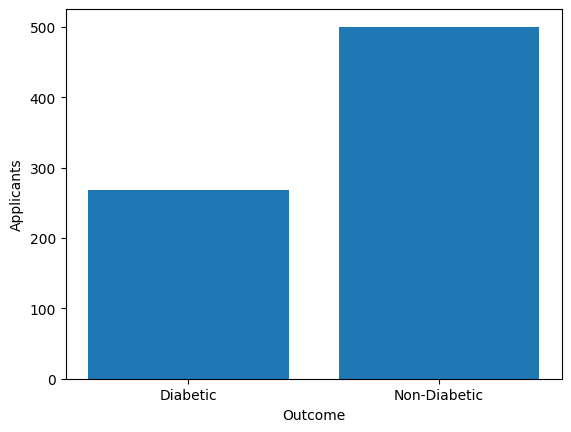

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

df['Outcome'].value_counts()
labels=['Diabetic','Non-Diabetic']
diabetic= (df['Outcome']==1).sum()
non_diabetic = (df['Outcome']==0).sum()
values=[diabetic,non_diabetic]
plt.bar(labels,values)
plt.xlabel("Outcome")
plt.ylabel("Applicants")
plt.show()

# Gemini Assissted Analysis
The diabetes.csv dataset contains 768 records and 9 columns with numerical values used to predict the onset of diabetes based on diagnostic measures.

**Dataset Structure and Summary**
Dimensions: 768 rows and 9 columns
DataTypes: All columns are numeric(7 int values and 2 float)
Target Variable: Outcome. 1 denotes patients with diabetes and 0 for patients without diabetes.500 without diabetes(1) and 268 with diabetes(1)

**Hidden Missing Values**
In the given dataset several biological features contain values as 0 which is not correct, hence treated as missing values.
Insulin: 374 missing values
SkinThickness:227 missing values
BloodPressure: 35 missing values
BMI: 11 missing values
Glucose: 5 missing values


In [26]:
# Handle Hidden missing values(0 values for the biological values)
cols_with_zeroes=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
df[cols_with_zeroes]=df[cols_with_zeroes].replace(0,np.nan)
df[cols_with_zeroes]=df[cols_with_zeroes].fillna(df[cols_with_zeroes].median())

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [13]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
# LabelEncoder not used

In [17]:
# Split data to independent features and target outcome
x=df.drop(['Outcome'],axis=1)
y=df['Outcome']

x.head()
#y.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


In [18]:
from sklearn.model_selection import train_test_split

In [40]:
# Splitting data to train and test datasets.
# 80% size set for training data and remaining 20% will be test set.
x_train,x_test,y_train,y_test= train_test_split(x,y,train_size=0.80,stratify=y)

In [48]:
#. Preprocessing: Scale numerical features
# Scaling numerical features prevents variables with large numbers from dominating the model
# and evaluation are correct

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

#PART 2 - ML Model Building

In [49]:
# Importing the LogisticRegression model
# Logistic regression model is used as the outcome is not a liner value,
# outcome is decided based on a combination of different values
from sklearn.linear_model import LogisticRegression
model= LogisticRegression()

#PART 3 - Model Training


In [50]:
# training the model using training data
model.fit(x_train_scaled,y_train)

LogisticRegression()

In [52]:
# Generate predictions using training set
train_predictions = model.predict(x_train_scaled)
test_predictions = model.predict(x_test_scaled)

In [54]:
# Check Accuracy of predictions
from sklearn.metrics import accuracy_score

train_accuracy_score = accuracy_score(y_train,train_predictions)
test_accuracy_score = accuracy_score(y_test,test_predictions)

print(f"Training set Accuracy Score:{train_accuracy_score}")
print(f"Testset Accuracy Score:{test_accuracy_score}")

Training set Accuracy Score:0.7736156351791531
Testset Accuracy Score:0.7662337662337663


In [55]:
from sklearn.metrics import precision_score, recall_score,f1_score, confusion_matrix
precision = precision_score(y_test,test_predictions)
recall=recall_score(y_test,test_predictions)
f1=f1_score(y_test,test_predictions)
conf_matrix= confusion_matrix(y_test,test_predictions)

print(test_accuracy_score)
print(precision)
print(recall)
print(f1)
print(conf_matrix)

0.7662337662337663
0.6875
0.6111111111111112
0.6470588235294118
[[85 15]
 [21 33]]
